# Generating Training Data

In this notebook, the bubble dynamics model is used to generate and store training data.

In [1]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import numpy as np

import wavelet_transform.utils.training_data as train
import wavelet_transform.utils.statistical_features as stats
import wavelet_transform.wpt.transform as wpt
import wavelet_transform.wpt.inverse_transform as inv

In [2]:
sampling_rate = 50e6

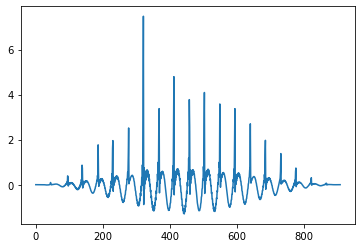

,level,node number,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,1,0,"(0.0, 1.25e7)",6250000.0,303.512830,2.482177,0.640322,-0.193601,11.142528,7.040415,1.549953,1.549953,4.645009,4.984413,3.909920
1,1,1,"(1.25e7, 2.5e7)",18750000.0,73.999362,1.869228,0.156117,-0.806550,36.041302,6.272511,-2.323100,2.323100,3.447270,7.436299,0.995151


,level,node number,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,0,0,"(0.0, 2.5e7)",12500000.0,377.511384,2.57693,0.415304,-0.381634,32.358767,11.606519,3.571302,3.571302,4.669763,6.082182,4.669763


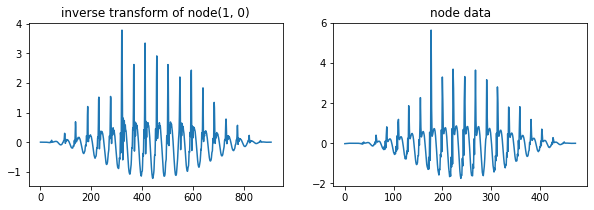

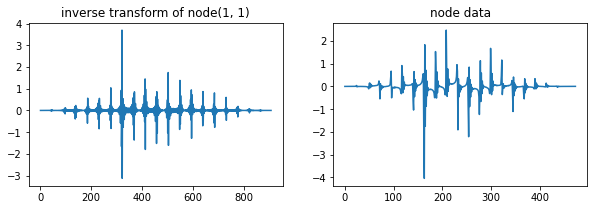

In [3]:
data = train.get_data(R_init=1e-06, frequency=11e5, pac=-60e4, sampling_rate=50e6)

data = (data - np.mean(data)) / np.std(data)
data *= np.hanning(len(data))
# data += np.random.normal(0, 0.05, len(data))

plt.plot(data)
plt.show()

tr_obj = wpt.dwpt(data, max_level=6, wavelet="db20", 
                  mode="symmetric", min_entropy=True, min_level=1
)
tr_obj.calc_frequencies(sampling_rate)
display(tr_obj.info(leaf_nodes=True))
display(tr_obj.info(0))
# print(sum(tr_obj.info(level=2)["level entropy"]))

for node in tr_obj.get_leaf_nodes():
    inverse = inv.inv_dwpt(tr_obj, node.level, nodes=node)

    # Plot inverse and node data
    fig, ax = plt.subplots(1,2)
    fig.set_size_inches(10, 3)
    ax[0].plot(inverse)
    ax[0].set_title(f"inverse transform of node{node.level, node.node_number}")
    ax[1].plot(node.data)
    ax[1].set_title("node data")
    plt.show()

### Model testing

Generating signals using the bubble dynamics model

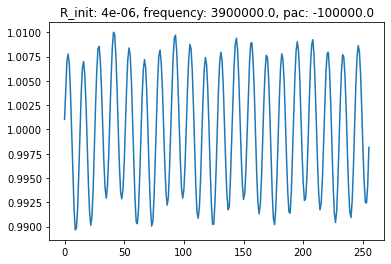

1.581647089308108


In [4]:
R_init = 4e-6
frequency = 3.9e6
pac = -1e5

# Read generated data or generate data and store it
data = train.get_data(R_init, frequency, pac, sampling_rate)  # uses default values for other parameters
if data is None:
    raise ValueError("data could not be generated")

plt.plot(data)
plt.title(f"R_init: {R_init}, frequency: {frequency}, pac: {pac}")
plt.show()

print(stats.kurtosis(data))

### Generating Training Data

Generating training data under a range of intensity (pac), frequency, initial bubble radius (R_init)

1e-06 700000.0 -10000.0
1e-06 700000.0 -20000.0
1e-06 700000.0 -30000.0
1e-06 700000.0 -40000.0
1e-06 700000.0 -50000.0
1e-06 700000.0 -60000.0
1e-06 700000.0 -70000.0
1e-06 700000.0 -80000.0
1e-06 700000.0 -90000.0
1e-06 700000.0 -100000.0
1e-06 700000.0 -110000.0
1e-06 700000.0 -120000.0
1e-06 700000.0 -130000.0
1e-06 700000.0 -140000.0
1e-06 700000.0 -150000.0
1e-06 700000.0 -160000.0
1e-06 700000.0 -170000.0


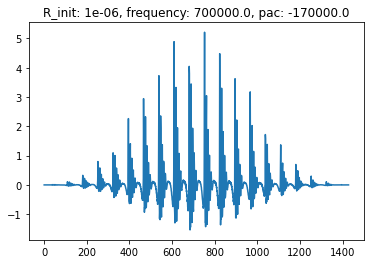

1e-06 700000.0 -180000.0


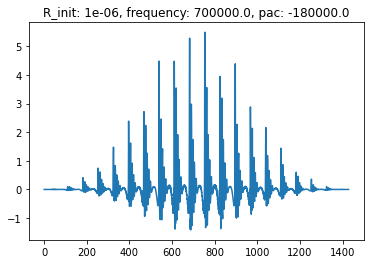

1e-06 700000.0 -190000.0


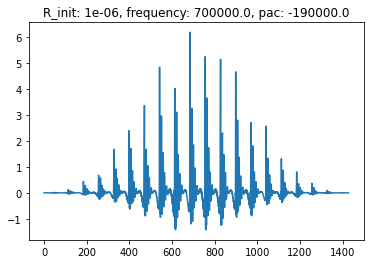

1e-06 800000.0 -10000.0
1e-06 800000.0 -20000.0
1e-06 800000.0 -30000.0
1e-06 800000.0 -40000.0
1e-06 800000.0 -50000.0
1e-06 800000.0 -60000.0
1e-06 800000.0 -70000.0
1e-06 800000.0 -80000.0
1e-06 800000.0 -90000.0
1e-06 800000.0 -100000.0
1e-06 800000.0 -110000.0
1e-06 800000.0 -120000.0
1e-06 800000.0 -130000.0
1e-06 800000.0 -140000.0
1e-06 800000.0 -150000.0
1e-06 800000.0 -160000.0
1e-06 800000.0 -170000.0


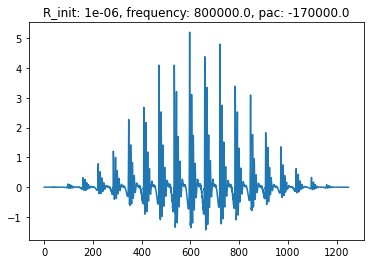

1e-06 800000.0 -180000.0


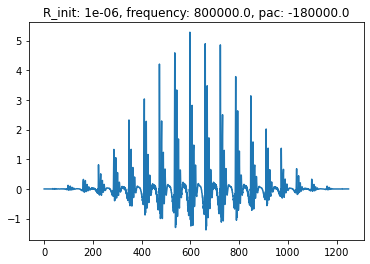

1e-06 800000.0 -190000.0


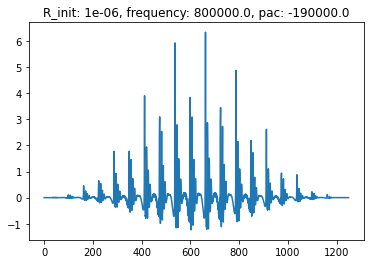

1e-06 900000.0 -10000.0
1e-06 900000.0 -20000.0
1e-06 900000.0 -30000.0
1e-06 900000.0 -40000.0
1e-06 900000.0 -50000.0
1e-06 900000.0 -60000.0
1e-06 900000.0 -70000.0
1e-06 900000.0 -80000.0
1e-06 900000.0 -90000.0
1e-06 900000.0 -100000.0
1e-06 900000.0 -110000.0
1e-06 900000.0 -120000.0
1e-06 900000.0 -130000.0
1e-06 900000.0 -140000.0
1e-06 900000.0 -150000.0
1e-06 900000.0 -160000.0
1e-06 900000.0 -170000.0


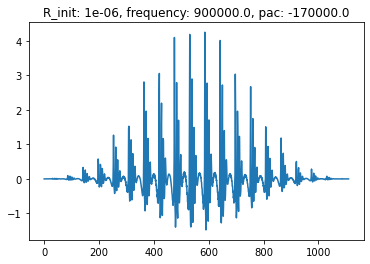

1e-06 900000.0 -180000.0


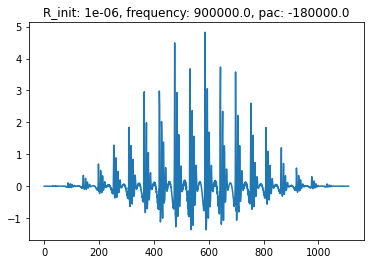

1e-06 900000.0 -190000.0


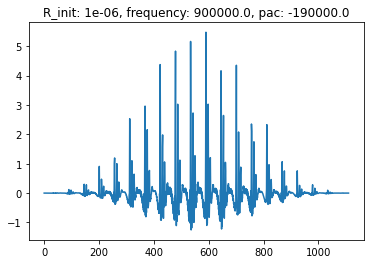

2e-06 700000.0 -10000.0
2e-06 700000.0 -20000.0
2e-06 700000.0 -30000.0
2e-06 700000.0 -40000.0
2e-06 700000.0 -50000.0
2e-06 700000.0 -60000.0
2e-06 700000.0 -70000.0
2e-06 700000.0 -80000.0
2e-06 700000.0 -90000.0
2e-06 700000.0 -100000.0
2e-06 700000.0 -110000.0
2e-06 700000.0 -120000.0


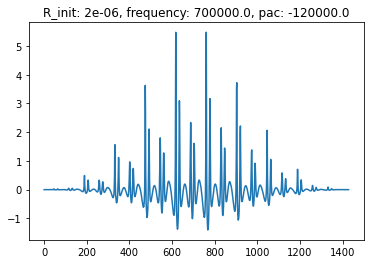

2e-06 700000.0 -130000.0


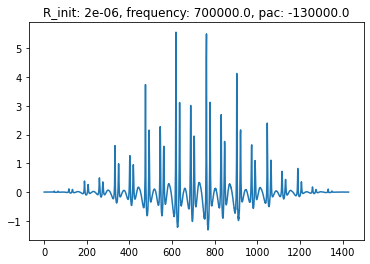

2e-06 700000.0 -140000.0


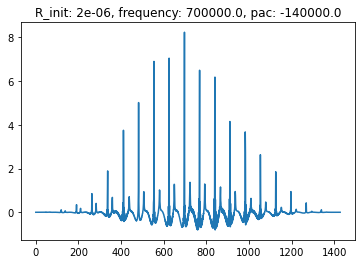

2e-06 700000.0 -150000.0


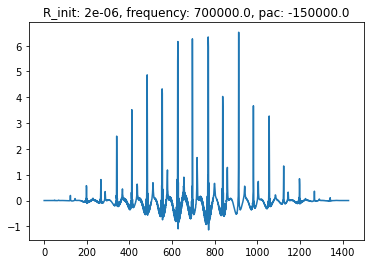

2e-06 700000.0 -160000.0


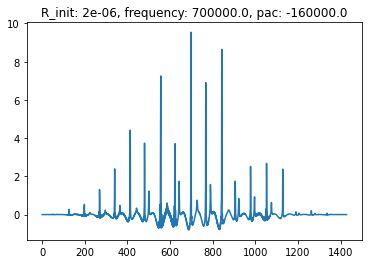

2e-06 700000.0 -170000.0


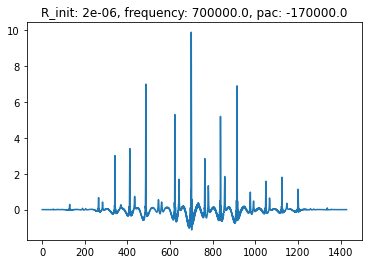

2e-06 700000.0 -180000.0


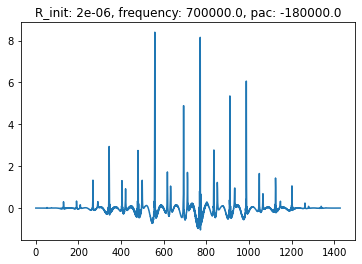

2e-06 700000.0 -190000.0


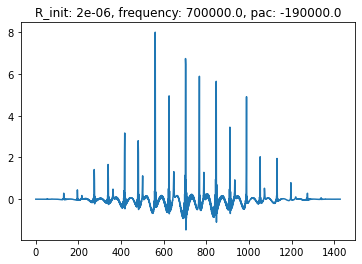

2e-06 800000.0 -10000.0
2e-06 800000.0 -20000.0
2e-06 800000.0 -30000.0
2e-06 800000.0 -40000.0
2e-06 800000.0 -50000.0
2e-06 800000.0 -60000.0
2e-06 800000.0 -70000.0
2e-06 800000.0 -80000.0
2e-06 800000.0 -90000.0
2e-06 800000.0 -100000.0
2e-06 800000.0 -110000.0
2e-06 800000.0 -120000.0


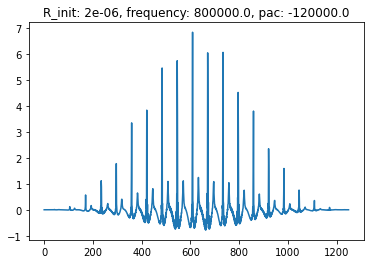

2e-06 800000.0 -130000.0


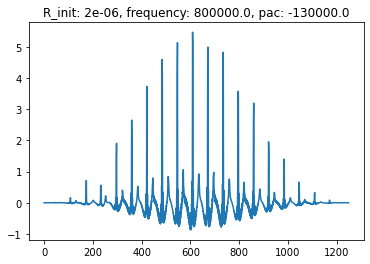

2e-06 800000.0 -140000.0


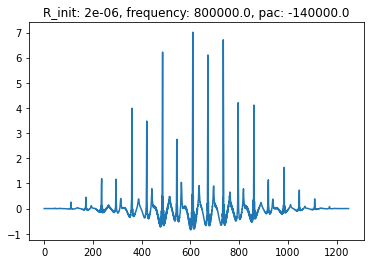

2e-06 800000.0 -150000.0


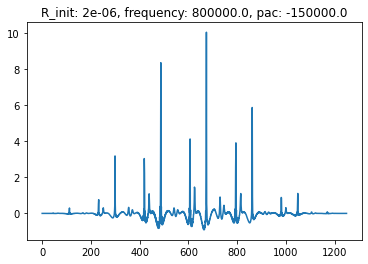

2e-06 800000.0 -160000.0


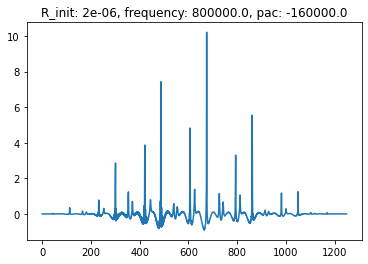

2e-06 800000.0 -170000.0


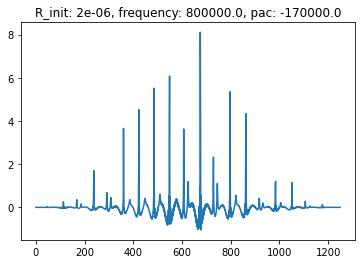

2e-06 800000.0 -180000.0


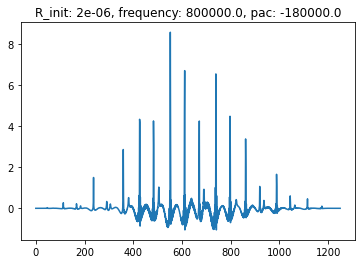

2e-06 800000.0 -190000.0


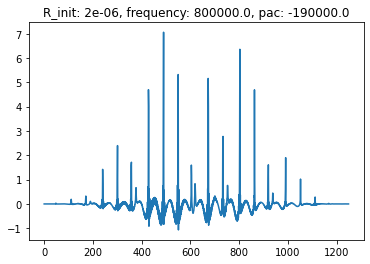

2e-06 900000.0 -10000.0
2e-06 900000.0 -20000.0
2e-06 900000.0 -30000.0
2e-06 900000.0 -40000.0
2e-06 900000.0 -50000.0
2e-06 900000.0 -60000.0
2e-06 900000.0 -70000.0
2e-06 900000.0 -80000.0


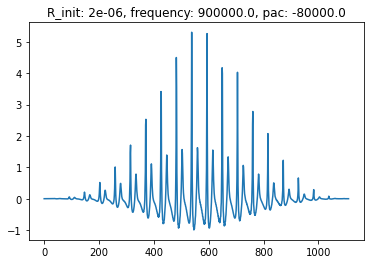

2e-06 900000.0 -90000.0


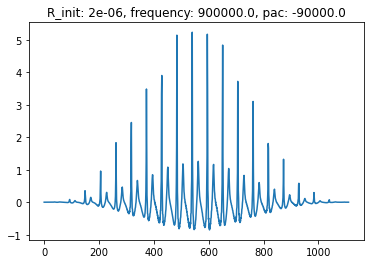

2e-06 900000.0 -100000.0


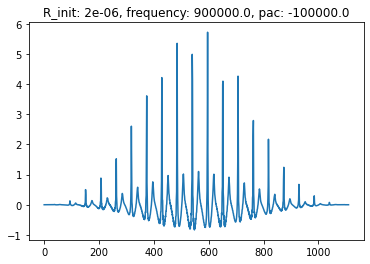

2e-06 900000.0 -110000.0


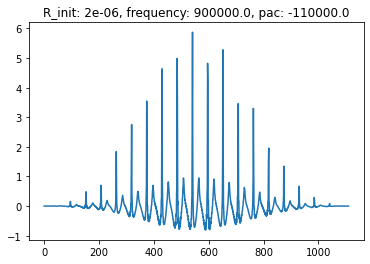

2e-06 900000.0 -120000.0


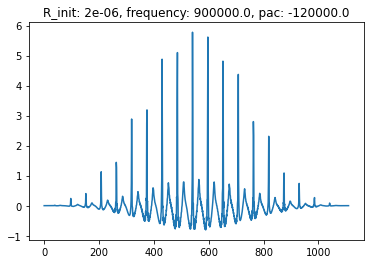

2e-06 900000.0 -130000.0


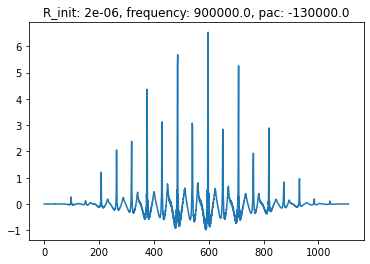

2e-06 900000.0 -140000.0


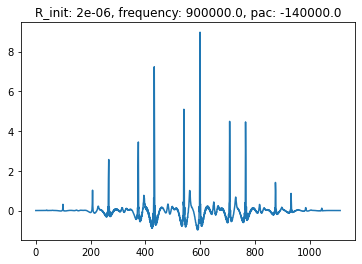

2e-06 900000.0 -150000.0


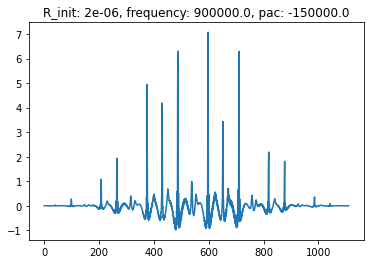

2e-06 900000.0 -160000.0


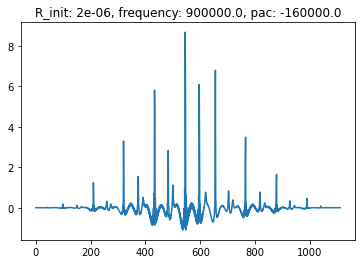

2e-06 900000.0 -170000.0


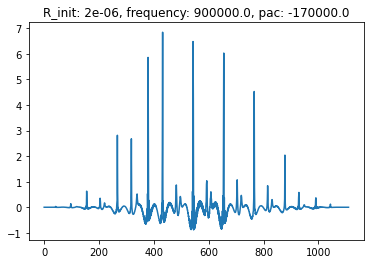

2e-06 900000.0 -180000.0


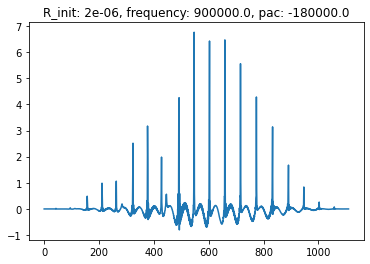

2e-06 900000.0 -190000.0


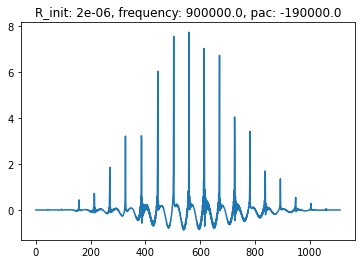

3e-06 700000.0 -10000.0
3e-06 700000.0 -20000.0
3e-06 700000.0 -30000.0
3e-06 700000.0 -40000.0
3e-06 700000.0 -50000.0
3e-06 700000.0 -60000.0
3e-06 700000.0 -70000.0
3e-06 700000.0 -80000.0
3e-06 700000.0 -90000.0
3e-06 700000.0 -100000.0
3e-06 700000.0 -110000.0


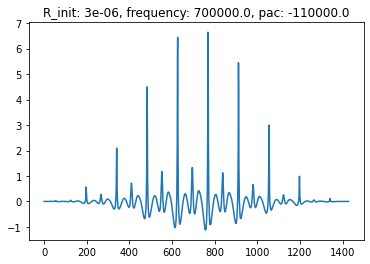

3e-06 700000.0 -120000.0


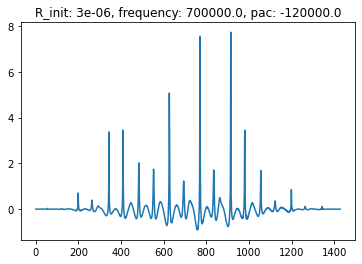

3e-06 700000.0 -130000.0


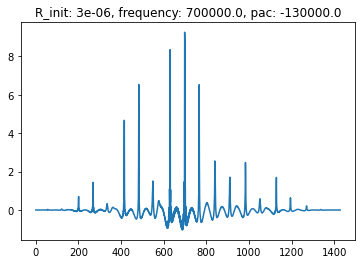

3e-06 700000.0 -140000.0


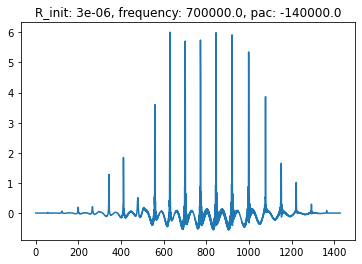

3e-06 700000.0 -150000.0


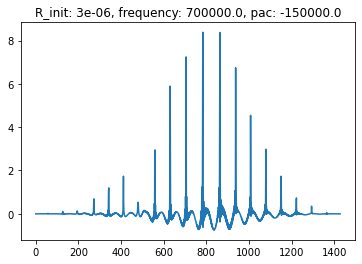

3e-06 700000.0 -160000.0


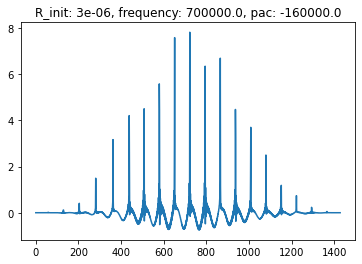

3e-06 700000.0 -170000.0


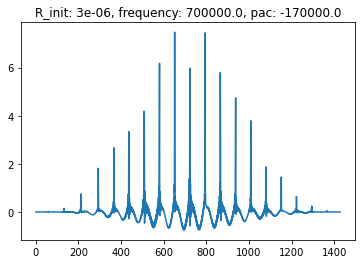

3e-06 700000.0 -180000.0


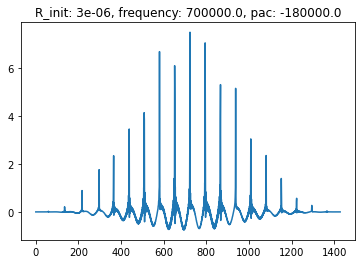

3e-06 700000.0 -190000.0


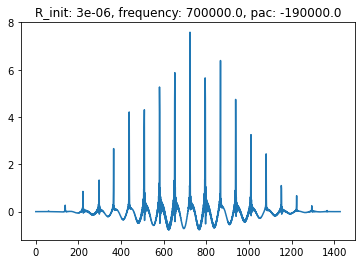

3e-06 800000.0 -10000.0
3e-06 800000.0 -20000.0
3e-06 800000.0 -30000.0
3e-06 800000.0 -40000.0
3e-06 800000.0 -50000.0
3e-06 800000.0 -60000.0
3e-06 800000.0 -70000.0
3e-06 800000.0 -80000.0
3e-06 800000.0 -90000.0
3e-06 800000.0 -100000.0
3e-06 800000.0 -110000.0
3e-06 800000.0 -120000.0


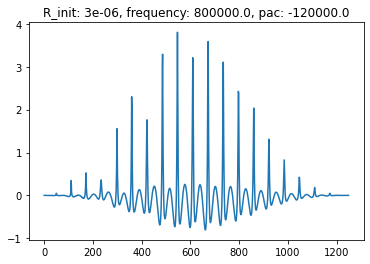

3e-06 800000.0 -130000.0


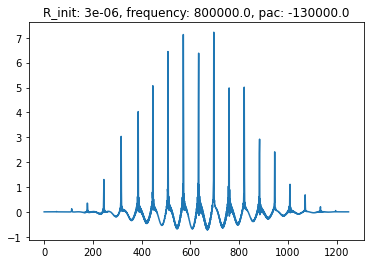

3e-06 800000.0 -140000.0


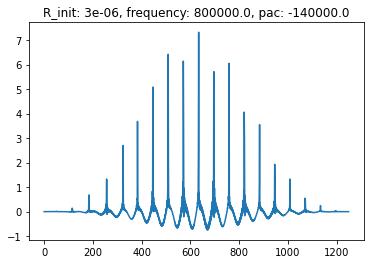

3e-06 800000.0 -150000.0


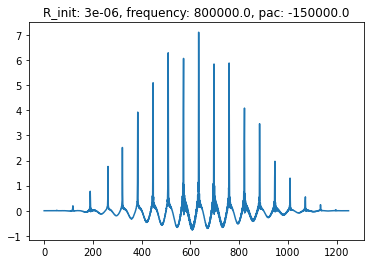

3e-06 800000.0 -160000.0


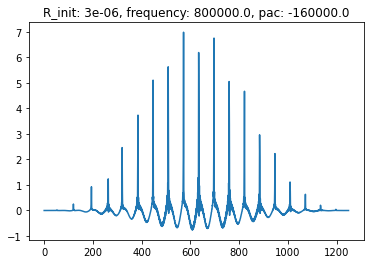

3e-06 800000.0 -170000.0


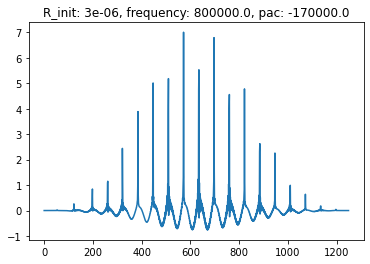

3e-06 800000.0 -180000.0


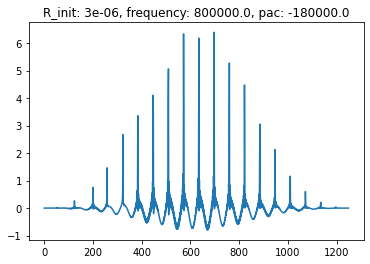

3e-06 800000.0 -190000.0


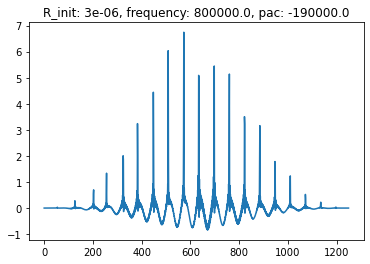

3e-06 900000.0 -10000.0
3e-06 900000.0 -20000.0
3e-06 900000.0 -30000.0
3e-06 900000.0 -40000.0
3e-06 900000.0 -50000.0
3e-06 900000.0 -60000.0
3e-06 900000.0 -70000.0
3e-06 900000.0 -80000.0
3e-06 900000.0 -90000.0
3e-06 900000.0 -100000.0


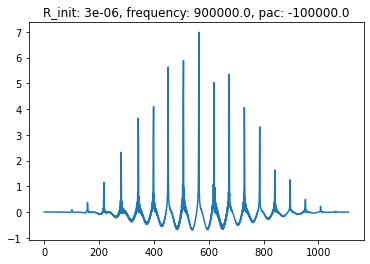

3e-06 900000.0 -110000.0


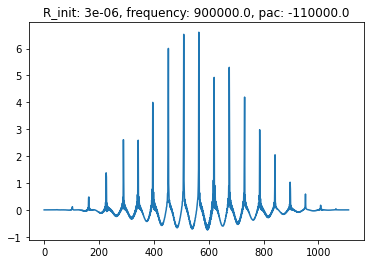

3e-06 900000.0 -120000.0


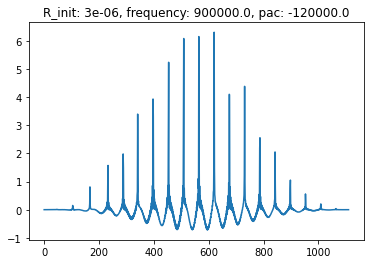

3e-06 900000.0 -130000.0


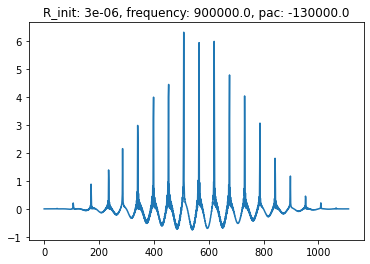

3e-06 900000.0 -140000.0


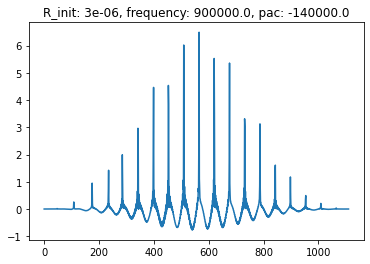

3e-06 900000.0 -150000.0


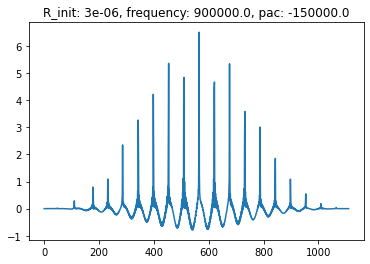

3e-06 900000.0 -160000.0
3e-06 900000.0 -170000.0


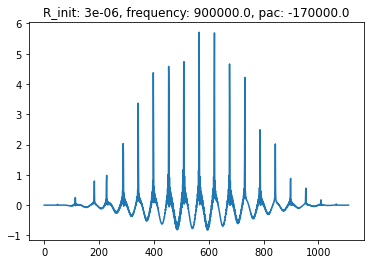

3e-06 900000.0 -180000.0


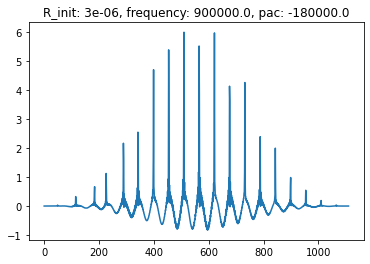

3e-06 900000.0 -190000.0


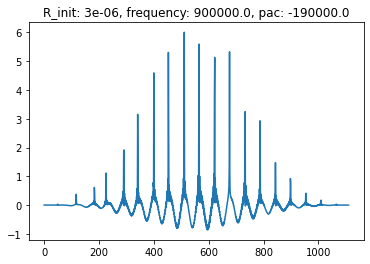

4e-06 700000.0 -10000.0
4e-06 700000.0 -20000.0
4e-06 700000.0 -30000.0
4e-06 700000.0 -40000.0
4e-06 700000.0 -50000.0
4e-06 700000.0 -60000.0
4e-06 700000.0 -70000.0


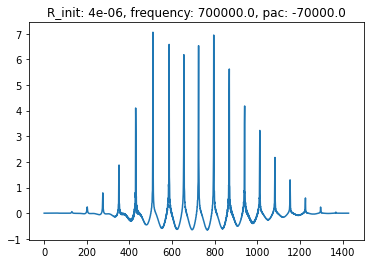

4e-06 700000.0 -80000.0


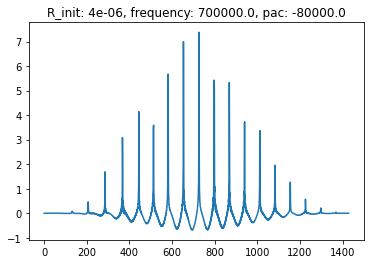

4e-06 700000.0 -90000.0


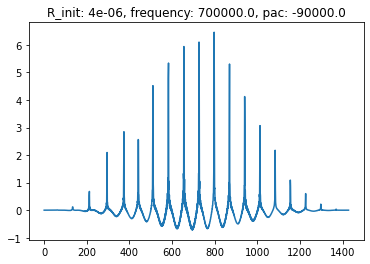

4e-06 700000.0 -100000.0


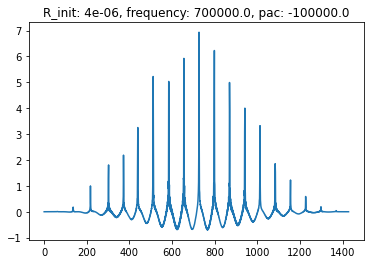

4e-06 700000.0 -110000.0


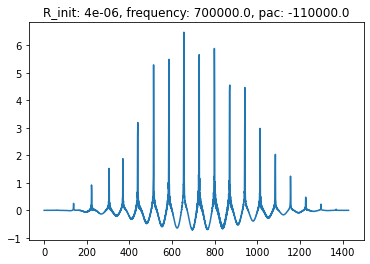

4e-06 700000.0 -120000.0


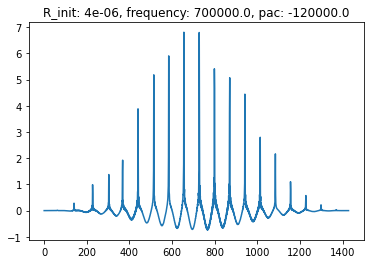

4e-06 700000.0 -130000.0


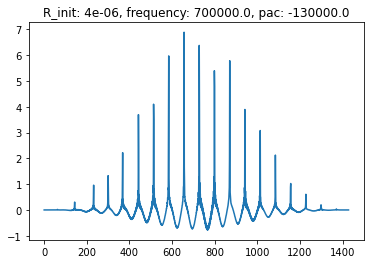

4e-06 700000.0 -140000.0


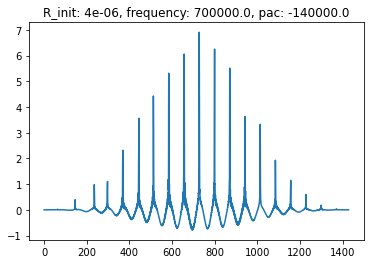

4e-06 700000.0 -150000.0


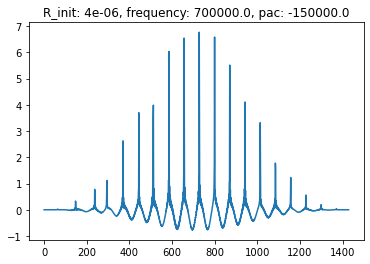

4e-06 700000.0 -160000.0


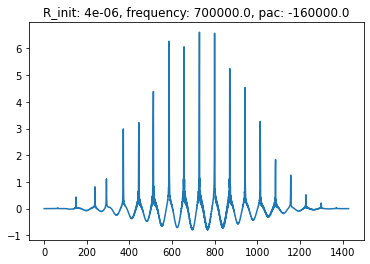

4e-06 700000.0 -170000.0


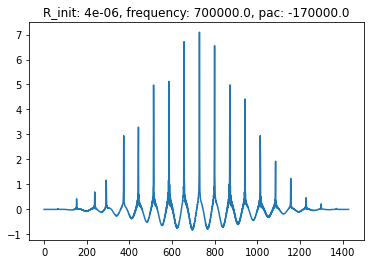

4e-06 700000.0 -180000.0


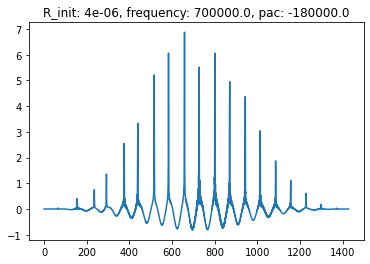

4e-06 700000.0 -190000.0


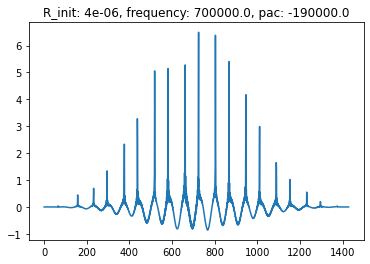

4e-06 800000.0 -10000.0
4e-06 800000.0 -20000.0
4e-06 800000.0 -30000.0


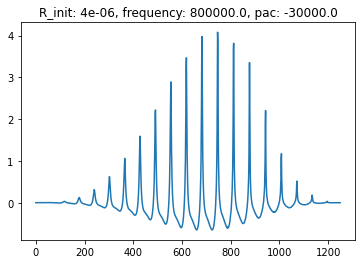

4e-06 800000.0 -40000.0


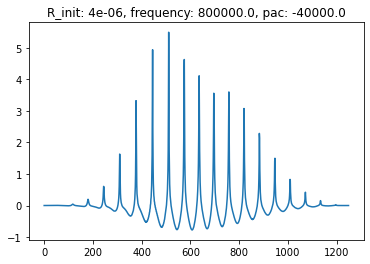

4e-06 800000.0 -50000.0


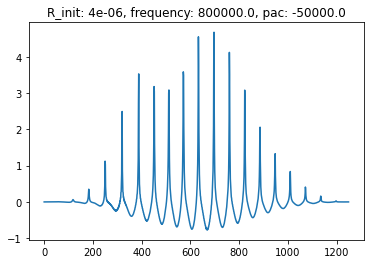

4e-06 800000.0 -60000.0


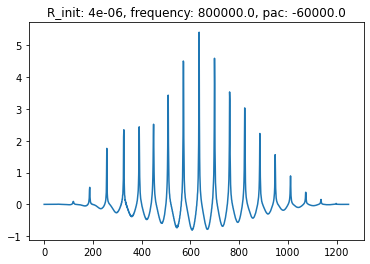

4e-06 800000.0 -70000.0


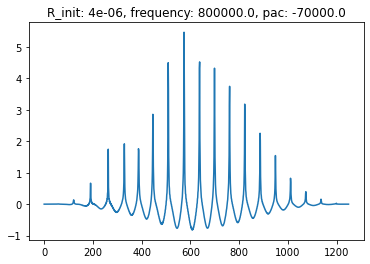

4e-06 800000.0 -80000.0


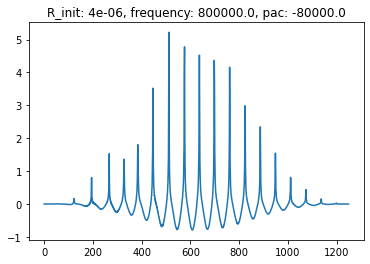

4e-06 800000.0 -90000.0


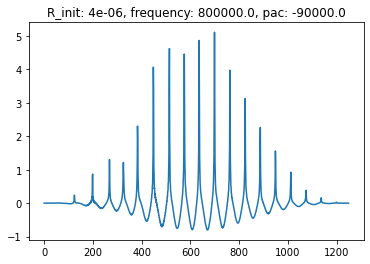

4e-06 800000.0 -100000.0


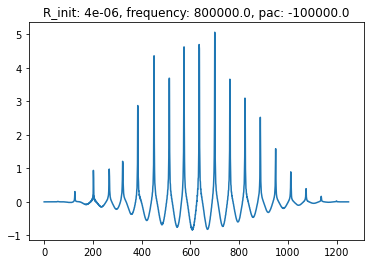

4e-06 800000.0 -110000.0


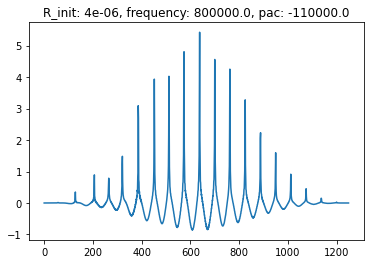

4e-06 800000.0 -120000.0


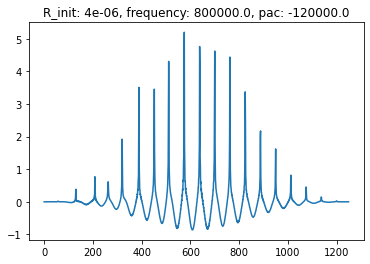

4e-06 800000.0 -130000.0


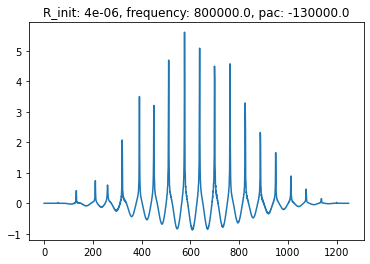

4e-06 800000.0 -140000.0


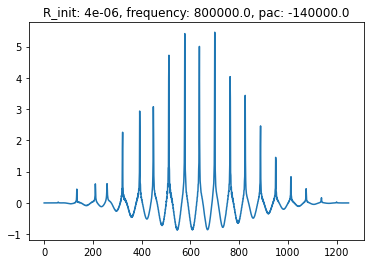

4e-06 800000.0 -150000.0


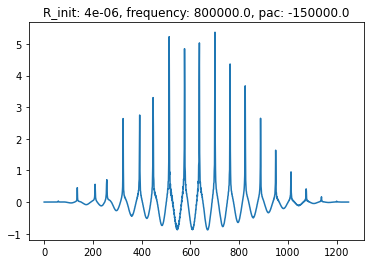

4e-06 800000.0 -160000.0


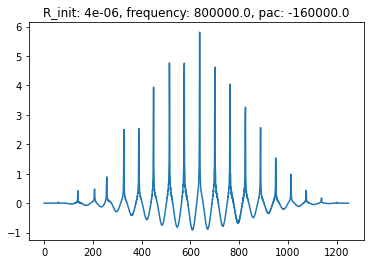

4e-06 800000.0 -170000.0


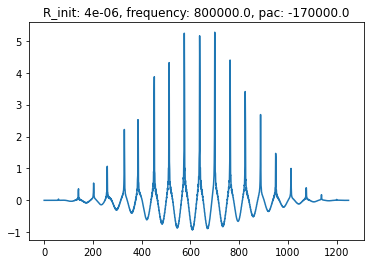

4e-06 800000.0 -180000.0


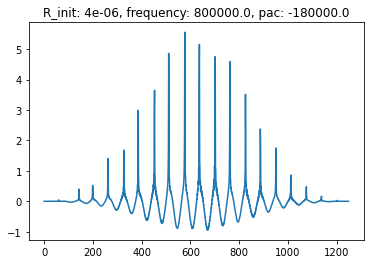

4e-06 800000.0 -190000.0


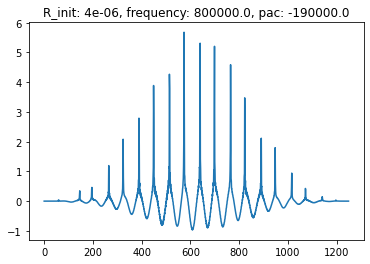

4e-06 900000.0 -10000.0
4e-06 900000.0 -20000.0
4e-06 900000.0 -30000.0
4e-06 900000.0 -40000.0
4e-06 900000.0 -50000.0
4e-06 900000.0 -60000.0
4e-06 900000.0 -70000.0
4e-06 900000.0 -80000.0
4e-06 900000.0 -90000.0
4e-06 900000.0 -100000.0
4e-06 900000.0 -110000.0
4e-06 900000.0 -120000.0
4e-06 900000.0 -130000.0
4e-06 900000.0 -140000.0
4e-06 900000.0 -150000.0
4e-06 900000.0 -160000.0
4e-06 900000.0 -170000.0
4e-06 900000.0 -180000.0
4e-06 900000.0 -190000.0


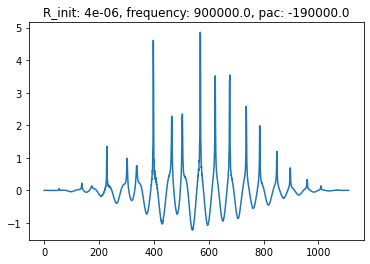

5e-06 700000.0 -10000.0
5e-06 700000.0 -20000.0
5e-06 700000.0 -30000.0
5e-06 700000.0 -40000.0
5e-06 700000.0 -50000.0
5e-06 700000.0 -60000.0
5e-06 700000.0 -70000.0
5e-06 700000.0 -80000.0
5e-06 700000.0 -90000.0
5e-06 700000.0 -100000.0
5e-06 700000.0 -110000.0
5e-06 700000.0 -120000.0
5e-06 700000.0 -130000.0
5e-06 700000.0 -140000.0
5e-06 700000.0 -150000.0
5e-06 700000.0 -160000.0
5e-06 700000.0 -170000.0
5e-06 700000.0 -180000.0


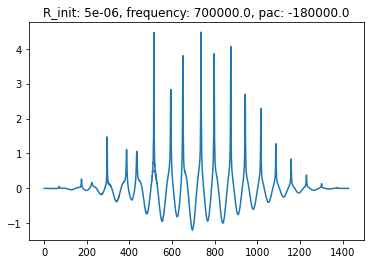

5e-06 700000.0 -190000.0


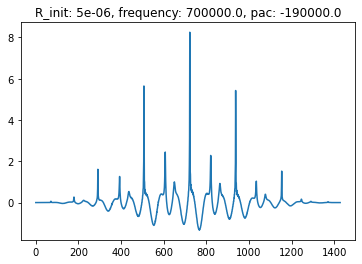

5e-06 800000.0 -10000.0
5e-06 800000.0 -20000.0
5e-06 800000.0 -30000.0
5e-06 800000.0 -40000.0
5e-06 800000.0 -50000.0
5e-06 800000.0 -60000.0
5e-06 800000.0 -70000.0
5e-06 800000.0 -80000.0
5e-06 800000.0 -90000.0
5e-06 800000.0 -100000.0
5e-06 800000.0 -110000.0
5e-06 800000.0 -120000.0
5e-06 800000.0 -130000.0
5e-06 800000.0 -140000.0
5e-06 800000.0 -150000.0
5e-06 800000.0 -160000.0
5e-06 800000.0 -170000.0
5e-06 800000.0 -180000.0
5e-06 800000.0 -190000.0


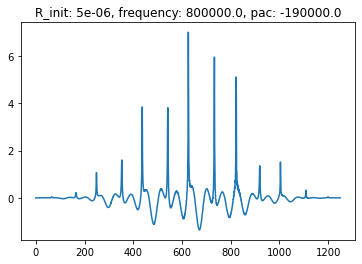

5e-06 900000.0 -10000.0
5e-06 900000.0 -20000.0
5e-06 900000.0 -30000.0
5e-06 900000.0 -40000.0
5e-06 900000.0 -50000.0
5e-06 900000.0 -60000.0
5e-06 900000.0 -70000.0
5e-06 900000.0 -80000.0
5e-06 900000.0 -90000.0
5e-06 900000.0 -100000.0
5e-06 900000.0 -110000.0
5e-06 900000.0 -120000.0
5e-06 900000.0 -130000.0
5e-06 900000.0 -140000.0
5e-06 900000.0 -150000.0
5e-06 900000.0 -160000.0
5e-06 900000.0 -170000.0


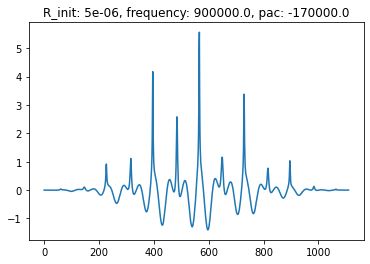

5e-06 900000.0 -180000.0


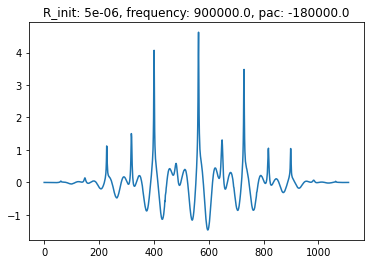

5e-06 900000.0 -190000.0


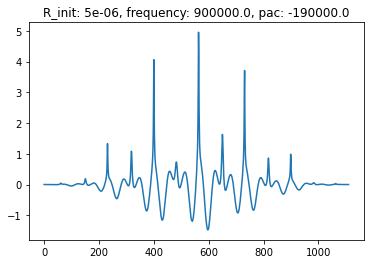

6e-06 700000.0 -10000.0
6e-06 700000.0 -20000.0
6e-06 700000.0 -30000.0
6e-06 700000.0 -40000.0
6e-06 700000.0 -50000.0
6e-06 700000.0 -60000.0
6e-06 700000.0 -70000.0
6e-06 700000.0 -80000.0
6e-06 700000.0 -90000.0
6e-06 700000.0 -100000.0
6e-06 700000.0 -110000.0
6e-06 700000.0 -120000.0
6e-06 700000.0 -130000.0
6e-06 700000.0 -140000.0
6e-06 700000.0 -150000.0
6e-06 700000.0 -160000.0
6e-06 700000.0 -170000.0


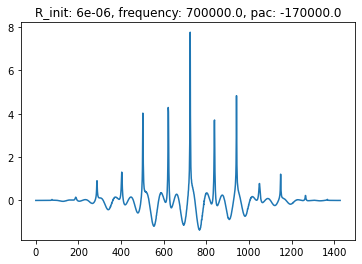

6e-06 700000.0 -180000.0


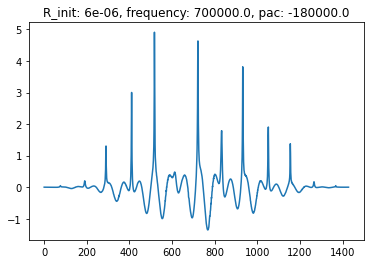

6e-06 700000.0 -190000.0
6e-06 800000.0 -10000.0
6e-06 800000.0 -20000.0
6e-06 800000.0 -30000.0
6e-06 800000.0 -40000.0
6e-06 800000.0 -50000.0
6e-06 800000.0 -60000.0
6e-06 800000.0 -70000.0
6e-06 800000.0 -80000.0
6e-06 800000.0 -90000.0
6e-06 800000.0 -100000.0
6e-06 800000.0 -110000.0
6e-06 800000.0 -120000.0
6e-06 800000.0 -130000.0
6e-06 800000.0 -140000.0
6e-06 800000.0 -150000.0
6e-06 800000.0 -160000.0
6e-06 800000.0 -170000.0
6e-06 800000.0 -180000.0
6e-06 800000.0 -190000.0
6e-06 900000.0 -10000.0
6e-06 900000.0 -20000.0
6e-06 900000.0 -30000.0
6e-06 900000.0 -40000.0
6e-06 900000.0 -50000.0
6e-06 900000.0 -60000.0
6e-06 900000.0 -70000.0
6e-06 900000.0 -80000.0
6e-06 900000.0 -90000.0
6e-06 900000.0 -100000.0
6e-06 900000.0 -110000.0
6e-06 900000.0 -120000.0
6e-06 900000.0 -130000.0
6e-06 900000.0 -140000.0
6e-06 900000.0 -150000.0
6e-06 900000.0 -160000.0
6e-06 900000.0 -170000.0
6e-06 900000.0 -180000.0
6e-06 900000.0 -190000.0
7e-06 700000.0 -10000.0
7e-06 700000.0 -200

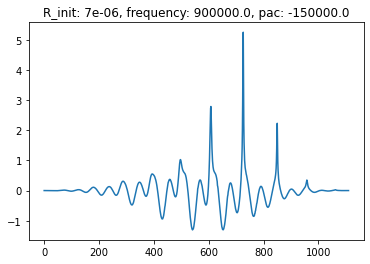

7e-06 900000.0 -160000.0


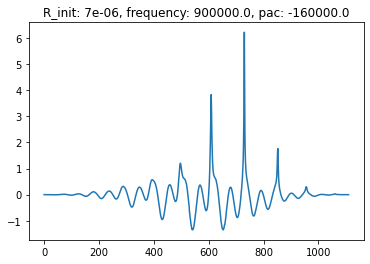

7e-06 900000.0 -170000.0


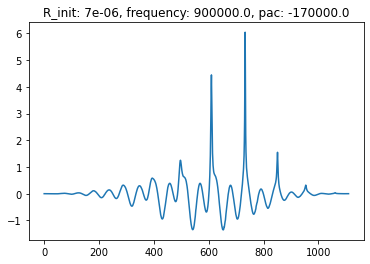

7e-06 900000.0 -180000.0


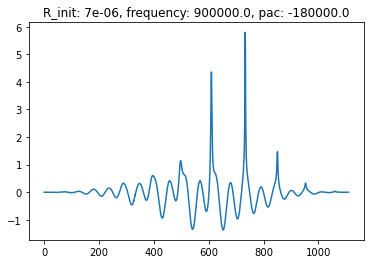

7e-06 900000.0 -190000.0


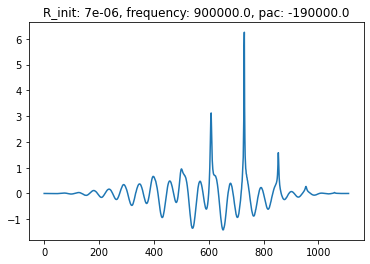

8e-06 700000.0 -10000.0
8e-06 700000.0 -20000.0
8e-06 700000.0 -30000.0
8e-06 700000.0 -40000.0
8e-06 700000.0 -50000.0
8e-06 700000.0 -60000.0
8e-06 700000.0 -70000.0
8e-06 700000.0 -80000.0
8e-06 700000.0 -90000.0
8e-06 700000.0 -100000.0
8e-06 700000.0 -110000.0
8e-06 700000.0 -120000.0
8e-06 700000.0 -130000.0
8e-06 700000.0 -140000.0
8e-06 700000.0 -150000.0
8e-06 700000.0 -160000.0
8e-06 700000.0 -170000.0
8e-06 700000.0 -180000.0
8e-06 700000.0 -190000.0


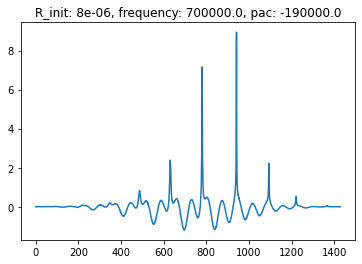

8e-06 800000.0 -10000.0
8e-06 800000.0 -20000.0
8e-06 800000.0 -30000.0
8e-06 800000.0 -40000.0
8e-06 800000.0 -50000.0
8e-06 800000.0 -60000.0
8e-06 800000.0 -70000.0
8e-06 800000.0 -80000.0
8e-06 800000.0 -90000.0
8e-06 800000.0 -100000.0
8e-06 800000.0 -110000.0
8e-06 800000.0 -120000.0
8e-06 800000.0 -130000.0
8e-06 800000.0 -140000.0
8e-06 800000.0 -150000.0
8e-06 800000.0 -160000.0
8e-06 800000.0 -170000.0
8e-06 800000.0 -180000.0
8e-06 800000.0 -190000.0


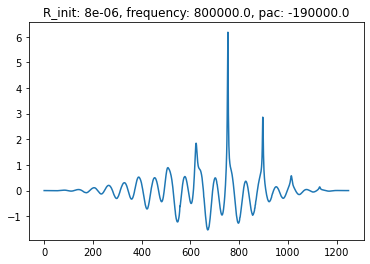

8e-06 900000.0 -10000.0
8e-06 900000.0 -20000.0
8e-06 900000.0 -30000.0
8e-06 900000.0 -40000.0
8e-06 900000.0 -50000.0
8e-06 900000.0 -60000.0
8e-06 900000.0 -70000.0
8e-06 900000.0 -80000.0
8e-06 900000.0 -90000.0
8e-06 900000.0 -100000.0
8e-06 900000.0 -110000.0
8e-06 900000.0 -120000.0
8e-06 900000.0 -130000.0
8e-06 900000.0 -140000.0
8e-06 900000.0 -150000.0
8e-06 900000.0 -160000.0
8e-06 900000.0 -170000.0
8e-06 900000.0 -180000.0
8e-06 900000.0 -190000.0
9e-06 700000.0 -10000.0
9e-06 700000.0 -20000.0
9e-06 700000.0 -30000.0
9e-06 700000.0 -40000.0
9e-06 700000.0 -50000.0
9e-06 700000.0 -60000.0
9e-06 700000.0 -70000.0
9e-06 700000.0 -80000.0
9e-06 700000.0 -90000.0
9e-06 700000.0 -100000.0
9e-06 700000.0 -110000.0
9e-06 700000.0 -120000.0
9e-06 700000.0 -130000.0
9e-06 700000.0 -140000.0
9e-06 700000.0 -150000.0


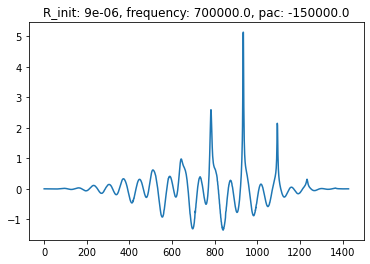

9e-06 700000.0 -160000.0


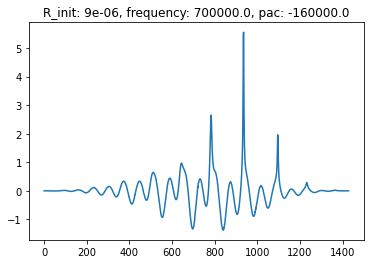

9e-06 700000.0 -170000.0


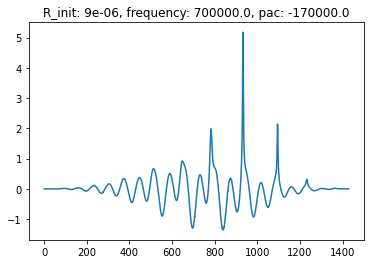

9e-06 700000.0 -180000.0
9e-06 700000.0 -190000.0
9e-06 800000.0 -10000.0
9e-06 800000.0 -20000.0
9e-06 800000.0 -30000.0
9e-06 800000.0 -40000.0
9e-06 800000.0 -50000.0
9e-06 800000.0 -60000.0
9e-06 800000.0 -70000.0
9e-06 800000.0 -80000.0
9e-06 800000.0 -90000.0
9e-06 800000.0 -100000.0
9e-06 800000.0 -110000.0
9e-06 800000.0 -120000.0
9e-06 800000.0 -130000.0
9e-06 800000.0 -140000.0
9e-06 800000.0 -150000.0
9e-06 800000.0 -160000.0
9e-06 800000.0 -170000.0
9e-06 800000.0 -180000.0
9e-06 800000.0 -190000.0
9e-06 900000.0 -10000.0
9e-06 900000.0 -20000.0
9e-06 900000.0 -30000.0
9e-06 900000.0 -40000.0
9e-06 900000.0 -50000.0
9e-06 900000.0 -60000.0
9e-06 900000.0 -70000.0
9e-06 900000.0 -80000.0
9e-06 900000.0 -90000.0
9e-06 900000.0 -100000.0
9e-06 900000.0 -110000.0
9e-06 900000.0 -120000.0
9e-06 900000.0 -130000.0
9e-06 900000.0 -140000.0
9e-06 900000.0 -150000.0
9e-06 900000.0 -160000.0
9e-06 900000.0 -170000.0
9e-06 900000.0 -180000.0
9e-06 900000.0 -190000.0
1e-05 700000.0 -10

In [5]:
for R_init in (i / 1E6 for i in range(1, 11)):
    for frequency in (i * 1E5 for i in range(7, 10)):
        for pac in (i * -1E4 for i in range(1, 20)):
            print(R_init, frequency, pac)     

            # Read generated data or generate it if it doesn't exist     
            data = train.get_data(R_init, frequency, pac, sampling_rate)
            data = (data - np.mean(data)) / np.std(data)
            data *= np.blackman(len(data))
            if data is None:
                raise ValueError("data could not be generated")

            c = stats.kurtosis(data)
            if c > 20:
                plt.plot(data)
                plt.title(f"R_init: {R_init}, frequency: {frequency}, pac: {pac}")
                plt.show()